# 01b — Fitting my fitness–fatigue model

**Question:** does training load predict my efficiency on a given run, and if so,
how long do fitness and fatigue last *for me*?

Model, fitted with each run as an observation
([proposal](../proposals/01-training-load-vs-performance.md)):

```
EF_run = β₀ + β·covariates + k₁·F(t; τ₁) − k₂·F(t; τ₂) + ε
covariates = intensity (fraction of HR reserve), log duration, hilly
F(t; τ) = Σ over days s before t of TRIMP_s · e^(−(t−s)/τ)
```

Order of work:
1. Fit on all data, and inspect the error surface over (τ₁, τ₂).
2. **Identifiability**: could this much data recover τ even if the model were true?
3. Uncertainty: moving-block bootstrap.
4. **Out-of-sample**: rolling-origin forecasts against baselines. This is the headline.
5. Independent check against race VDOT.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from goalsplit_research import data, datasets
from goalsplit_research.fitness_fatigue import (
    LoadTerms, fit_fixed, fit_grid, predict, ols_predict, moving_block_indices,
)

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (11, 3.2), "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(2026)

ds = data.fetch_dataset()
acts = data.activities_frame(ds)
runs = datasets.run_table(ds, acts).sort_values("localDate").reset_index(drop=True)
races = datasets.road_races(ds, acts)
daily = data.daily_frame(ds)["load"]

COVARIATES = ["intensity", "log_hours", "hilly"]
terms = LoadTerms(daily)
day_idx = terms.day_index(runs["localDate"])
X = runs[COVARIATES].to_numpy()
y = runs["ef"].to_numpy()
print(f"{len(runs)} runs · daily load from {daily.index.min():%d %b %Y} ({len(daily)} days)")

192 runs · daily load from 06 Feb 2024 (986 days)


## 1. Fit on all data

τ₁ (fitness) = 10 days · τ₂ (fatigue) = 9 days
k₁ = 8.35e-04 · k₂ = 6.80e-04
Time to peak response after a session: none (model implies no fatigue-then-gain shape)
R²: covariates only 0.263 → with load terms 0.425
Share of remaining variance explained by load: 0.220
Worst grid point is only 12.8% worse than the best — a flat surface means weakly identified time constants


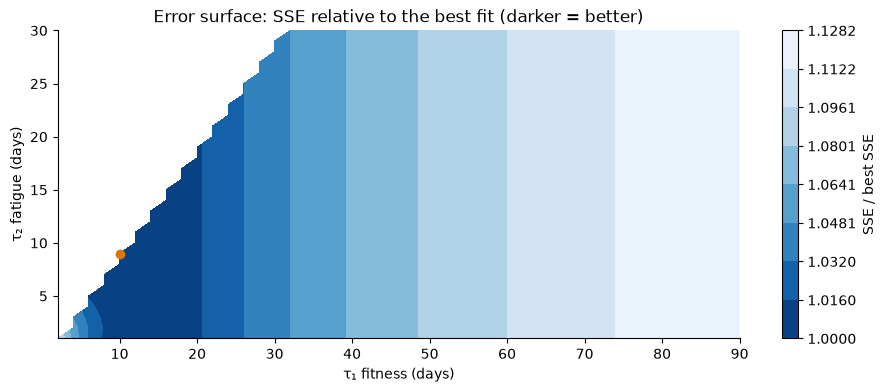

(τ₁, τ₂) pairs within 1% of the best SSE: 69 of 1125


In [2]:
full = fit_grid(terms, day_idx, X, y, keep_surface=True)
baseline_sse = float(((y - ols_predict(X, y, X)) ** 2).sum())
sst = float(((y - y.mean()) ** 2).sum())

print(f"τ₁ (fitness) = {full.tau1:.0f} days · τ₂ (fatigue) = {full.tau2:.0f} days")
print(f"k₁ = {full.k1:.2e} · k₂ = {full.k2:.2e}")
t_peak = full.time_to_peak()
print("Time to peak response after a session:", f"{t_peak:.1f} days" if t_peak else "none (model implies no fatigue-then-gain shape)")
print(f"R²: covariates only {1 - baseline_sse / sst:.3f} → with load terms {1 - full.sse / sst:.3f}")
print(f"Share of remaining variance explained by load: {1 - full.sse / baseline_sse:.3f}")

surf = full.surface.pivot(index="tau2", columns="tau1", values="sse")
rel = surf / full.sse
fig, ax = plt.subplots(figsize=(11, 4))
worst = float(np.nanmax(rel.values))
print(f"Worst grid point is only {100 * (worst - 1):.1f}% worse than the best — a flat surface means weakly identified time constants")
levels = np.unique(np.concatenate([[1.0], np.linspace(1.0, worst, 9)]))
im = ax.contourf(rel.columns, rel.index, rel.values, levels=levels, cmap="Blues_r")
ax.plot(full.tau1, full.tau2, "o", color="#d97706")
ax.set_xlabel("τ₁ fitness (days)"); ax.set_ylabel("τ₂ fatigue (days)")
ax.set_title("Error surface: SSE relative to the best fit (darker = better)")
fig.colorbar(im, ax=ax, label="SSE / best SSE")
plt.show()
within_1pct = (rel.values <= 1.01).sum()
print(f"(τ₁, τ₂) pairs within 1% of the best SSE: {within_1pct} of {np.isfinite(rel.values).sum()}")

### Is the second term doing anything?

If τ₁ and τ₂ come out close together, fitness and fatigue largely cancel and the
model may reduce to a single load term. Compare against one decaying load term
with a free time constant and a free sign.

Best single load term: τ = 13 days, coefficient +1.74e-04, R² = 0.425
Two-term fitness–fatigue model:                                  R² = 0.425


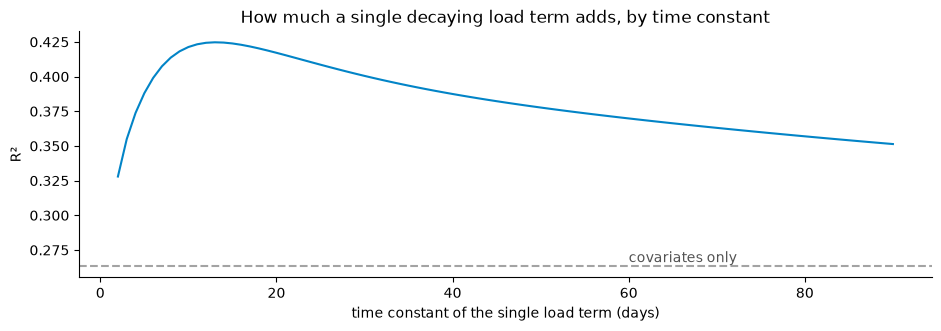

In [3]:
single = []
for tau in np.arange(2, 91, 1.0):
    A = np.column_stack([np.ones(len(y)), X, terms.at(tau, day_idx)])
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    single.append({"tau": tau, "r2": 1 - float(((y - A @ coef) ** 2).sum()) / sst, "coef": coef[-1]})
single = pd.DataFrame(single)
best_single = single.loc[single["r2"].idxmax()]
print(f"Best single load term: τ = {best_single['tau']:.0f} days, coefficient {best_single['coef']:+.2e}, R² = {best_single['r2']:.3f}")
print(f"Two-term fitness–fatigue model:                                  R² = {1 - full.sse / sst:.3f}")
ax = single.plot(x="tau", y="r2", legend=False, color="#0284c7")
ax.axhline(1 - baseline_sse / sst, color="#a3a3a3", linestyle="--")
ax.text(60, 1 - baseline_sse / sst + 0.003, "covariates only", color="#525252")
ax.set_xlabel("time constant of the single load term (days)"); ax.set_ylabel("R²")
ax.set_title("How much a single decaying load term adds, by time constant")
plt.show()

## 2. Identifiability: could we recover τ if the model were true?

A parametric bootstrap. Take the fitted model as the truth, simulate new EF
values with the same runs, dates, loads and residual noise, refit, and see how
widely the recovered τ₁ and τ₂ scatter. If they scatter across the whole grid,
this dataset can't pin the time constants down, however they're estimated.

In [4]:
fitted = predict(full, terms, day_idx, X)
noise_sd = np.sqrt(full.sse / (len(y) - len(full.beta) - 2))
recovered = []
for _ in range(40):
    y_sim = fitted + rng.normal(0, noise_sd, len(y))
    f = fit_grid(terms, day_idx, X, y_sim)
    recovered.append((f.tau1, f.tau2))
rec = pd.DataFrame(recovered, columns=["tau1", "tau2"])
print(f"True (fitted) τ₁ = {full.tau1:.0f}, τ₂ = {full.tau2:.0f}")
print(rec.describe(percentiles=[0.1, 0.5, 0.9]).loc[["10%", "50%", "90%"]].round(1).to_string())

True (fitted) τ₁ = 10, τ₂ = 9


     tau1  tau2
10%   6.0   1.0
50%  10.0   2.0
90%  14.2   8.1


## 3. Uncertainty on the real data: moving-block bootstrap

Resample blocks of 8 consecutive runs (about 4 weeks) to keep short-range
correlation, refit, repeat.

95% bootstrap intervals:
       tau1  tau2
0.025   2.0   1.0
0.500  12.0   7.0
0.975  27.7  17.0

Runs where the load terms collapsed (k₁ = 0 or k₂ = 0): 7%


Time to peak defined in 71% of resamples; 95% interval 1.2–11.6 days


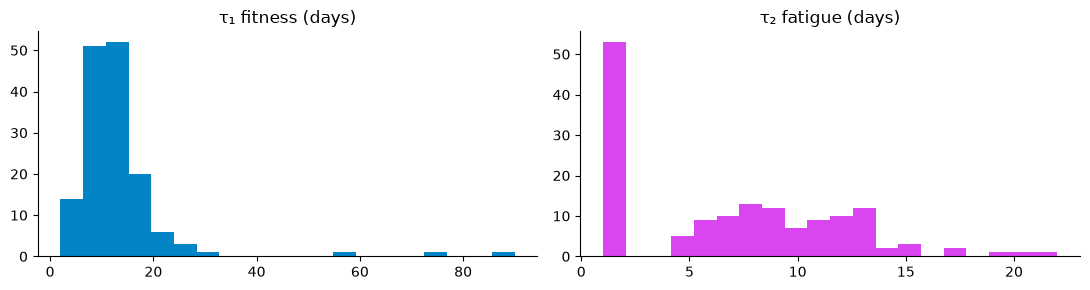

In [5]:
boot = []
for _ in range(150):
    idx = moving_block_indices(len(y), 8, rng)
    f = fit_grid(terms, day_idx[idx], X[idx], y[idx])
    boot.append({"tau1": f.tau1, "tau2": f.tau2, "k1": f.k1, "k2": f.k2, "t_peak": f.time_to_peak()})
boot = pd.DataFrame(boot)
summary = boot[["tau1", "tau2"]].quantile([0.025, 0.5, 0.975]).round(1)
print("95% bootstrap intervals:")
print(summary.to_string())
print(f"\nRuns where the load terms collapsed (k₁ = 0 or k₂ = 0): {((boot['k1'] == 0) | (boot['k2'] == 0)).mean():.0%}")
peaks = boot["t_peak"].dropna()
print(f"Time to peak defined in {len(peaks) / len(boot):.0%} of resamples" + (
    f"; 95% interval {peaks.quantile(0.025):.1f}–{peaks.quantile(0.975):.1f} days" if len(peaks) > 5 else ""))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(boot["tau1"], bins=20, color="#0284c7"); axes[0].set_title("τ₁ fitness (days)")
axes[1].hist(boot["tau2"], bins=20, color="#d946ef"); axes[1].set_title("τ₂ fatigue (days)")
plt.tight_layout(); plt.show()

## 4. Out-of-sample evaluation (the headline)

Rolling origin: fit on every run before a cutoff date, predict the runs in the
next 28 days, move the cutoff forward 28 days, repeat. Each model only ever sees
the past. Load terms use the training actually done up to the day before each
run — the question is "given the training I did, how efficient should this run
have been?".

| Model | What it knows |
|---|---|
| Covariates only | Duration, intensity, terrain — no load |
| Recent form | Covariates + the average residual of the last 28 days' runs (persistence) |
| CTL | Covariates + 42-day fitness only |
| Fitness–fatigue, default | Covariates + fitness (42 d) − fatigue (7 d), the textbook constants |
| Fitness–fatigue, fitted | Covariates + fitness − fatigue with τ₁, τ₂ re-fitted on each training window |

In [6]:
MIN_TRAIN_RUNS = 80
dates = runs["localDate"]
first_cut = dates.iloc[MIN_TRAIN_RUNS]
cutoffs = pd.date_range(first_cut, dates.max(), freq="28D")

rows = []
for fold, cut in enumerate(cutoffs):
    train = (dates < cut).to_numpy()
    test = ((dates >= cut) & (dates < cut + pd.Timedelta(days=28))).to_numpy()
    if test.sum() == 0:
        continue
    Xtr, ytr, Xte, yte = X[train], y[train], X[test], y[test]
    itr, ite = day_idx[train], day_idx[test]

    base_tr = ols_predict(Xtr, ytr, Xtr)
    preds = {"Covariates only": ols_predict(Xtr, ytr, Xte)}
    recent = (dates[train] >= cut - pd.Timedelta(days=28)).to_numpy()
    form = float((ytr - base_tr)[recent].mean()) if recent.any() else 0.0
    preds["Recent form"] = preds["Covariates only"] + form
    ctl = lambda i: terms.at(42, i)[:, None]
    preds["CTL"] = ols_predict(np.hstack([Xtr, ctl(itr)]), ytr, np.hstack([Xte, ctl(ite)]))
    preds["Fitness–fatigue, default"] = predict(fit_fixed(terms, itr, Xtr, ytr, 42, 7), terms, ite, Xte)
    fitted_fold = fit_grid(terms, itr, Xtr, ytr)
    preds["Fitness–fatigue, fitted"] = predict(fitted_fold, terms, ite, Xte)

    for model, p in preds.items():
        for actual, pred in zip(yte, p):
            rows.append({"fold": fold, "model": model, "sq_err": (actual - pred) ** 2, "abs_err": abs(actual - pred)})

errors = pd.DataFrame(rows)
n_folds = errors["fold"].nunique()
print(f"{n_folds} folds, {int((errors['model'] == 'Covariates only').sum())} held-out runs\n")

ref = errors[errors["model"] == "Covariates only"].reset_index(drop=True)
table = []
for model, g in errors.groupby("model", sort=False):
    g = g.reset_index(drop=True)
    diff = g["sq_err"] - ref["sq_err"]  # negative = better than covariates only
    # Fold-level block bootstrap of the MSE difference
    fold_ids = g["fold"].unique()
    boots = []
    for _ in range(2000):
        pick = rng.choice(fold_ids, size=len(fold_ids), replace=True)
        boots.append(np.concatenate([diff[g["fold"] == f].to_numpy() for f in pick]).mean())
    lo, hi = np.percentile(boots, [2.5, 97.5])
    table.append({
        "model": model,
        "RMSE": np.sqrt(g["sq_err"].mean()),
        "MAE": g["abs_err"].mean(),
        "skill vs covariates": 1 - g["sq_err"].mean() / ref["sq_err"].mean(),
        "ΔMSE 95% CI": f"[{lo:+.5f}, {hi:+.5f}]",
    })
results = pd.DataFrame(table)
print(results.round(4).to_string(index=False))
print("\nSkill > 0 means fewer squared errors than the covariates-only model;"
      " a ΔMSE interval entirely below 0 means reliably better.")

14 folds, 112 held-out runs



                   model   RMSE    MAE  skill vs covariates          ΔMSE 95% CI
         Covariates only 0.0752 0.0593               0.0000 [+0.00000, +0.00000]
             Recent form 0.0721 0.0556               0.0814 [-0.00292, +0.00140]
                     CTL 0.0713 0.0553               0.1006 [-0.00377, +0.00167]
Fitness–fatigue, default 0.0713 0.0553               0.1006 [-0.00361, +0.00167]
 Fitness–fatigue, fitted 0.0715 0.0554               0.0942 [-0.00375, +0.00178]

Skill > 0 means fewer squared errors than the covariates-only model; a ΔMSE interval entirely below 0 means reliably better.


## 5. Independent check: race VDOT

Races never enter the fit. If the fitted fitness–fatigue state reflects real
fitness, it should be higher on the days of better races.

Fitted fitness–fatigue state           Spearman ρ = +0.20  (95% CI -0.30 to +0.68, n = 15)


Default (42/7) fitness–fatigue state   Spearman ρ = +0.28  (95% CI -0.22 to +0.68, n = 15)


CTL (42-day fitness) alone             Spearman ρ = +0.28  (95% CI -0.24 to +0.69, n = 15)


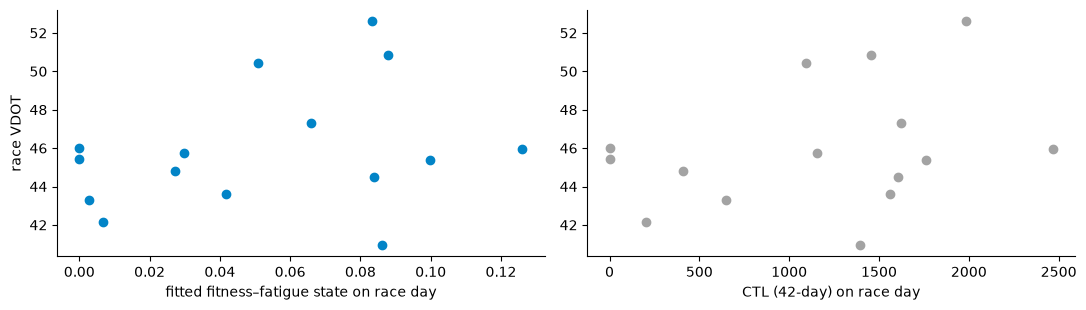

In [7]:
race_idx = terms.day_index(races["localDate"])
state_fitted = full.k1 * terms.at(full.tau1, race_idx) - full.k2 * terms.at(full.tau2, race_idx)
state_default_fit = fit_fixed(terms, day_idx, X, y, 42, 7)
state_default = state_default_fit.k1 * terms.at(42, race_idx) - state_default_fit.k2 * terms.at(7, race_idx)
ctl = terms.at(42, race_idx)

def rho_ci(a, b, n_boot=4000):
    a, b = np.asarray(a), np.asarray(b)
    r = spearmanr(a, b).statistic
    bs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(a), len(a))
        if len(np.unique(i)) > 3:
            bs.append(spearmanr(a[i], b[i]).statistic)
    return r, *np.nanpercentile(bs, [2.5, 97.5])

checks = {
    "Fitted fitness–fatigue state": state_fitted,
    "Default (42/7) fitness–fatigue state": state_default,
    "CTL (42-day fitness) alone": ctl,
}
for label, s in checks.items():
    r, lo, hi = rho_ci(s, races["vdot"])
    print(f"{label:<38} Spearman ρ = {r:+.2f}  (95% CI {lo:+.2f} to {hi:+.2f}, n = {len(races)})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].scatter(state_fitted, races["vdot"], color="#0284c7")
axes[0].set_xlabel("fitted fitness–fatigue state on race day"); axes[0].set_ylabel("race VDOT")
axes[1].scatter(ctl, races["vdot"], color="#a3a3a3")
axes[1].set_xlabel("CTL (42-day) on race day")
plt.tight_layout(); plt.show()

## Conclusions

**In sample, recent load matters.** Adding load terms lifts R² from 0.26 to 0.43,
explaining 22% of the EF variance the covariates leave behind.

**But the two-component model collapses to one.** The best fit has τ₁ = 10 and
τ₂ = 9 days. Fitness and fatigue nearly cancel, and a single positive load term with
τ = 13 days fits exactly as well (R² 0.425). The model implies no "fatigue first,
fitness later" response, so no time-to-peak or taper length can be read from it.

**The time constants aren't identifiable from this data.** The error surface is flat
(the worst of 1,125 grid points is only 12.8% worse than the best). In the parametric
bootstrap, a true τ₂ of 9 days is recovered with a median of 2. The moving-block
bootstrap puts τ₁ anywhere from 2 to 28 days.

**Out of sample, the gain is small and not reliable.**
- **H1 (load predicts performance):** every load model cuts squared forecast error
  by 9–10% against covariates alone, but every 95% interval on the difference
  includes zero, and a plain "recent form" baseline achieves 8%. Weak, not
  statistically reliable.
- **H2 (personal constants differ from 42/7):** not supported. Fitted constants
  forecast no better than the textbook ones (skill 0.094 vs 0.101).

**Race check: inconclusive.** Race VDOT correlates weakly and positively with
race-day load state (ρ ≈ +0.2 to +0.3), but with n = 15 the intervals run from −0.3
to +0.7.

**Interpretation.** Recent training load is positively associated with running
efficiency over about a two-week window. Shared heart-rate measurement can't explain
this: a high-HR day raises TRIMP but *lowers* EF, which biases the association the
other way. The more plausible alternatives are a genuine short-term training effect,
or reverse causation, where being healthy and in form drives both more training and
better efficiency, while illness and breaks lower both. Observational data can't
separate these by fit alone.

**Next (01c):** a lagged dose–response analysis that excludes the weeks around
breaks, and tests the reverse direction (does efficiency predict *subsequent* load?)
to probe reverse causation.